# C1_02_Overfit_Regularise
- X = X_flat_c1_v2.npy
- Y = y_labels_c1_v2.csv
- Built by Garmin_C1_DataBuild

### Overfit-then-regularise

Three dense networks, trained on the same TRAIN windows and scored on the same VAL windows:
1. **Baseline**: small network (16→8), the same as the Simple DNN, retrained for 100 epochs without early stopping (0.573 val accuracy).
2. **Overfit**: deliberately oversized (128→64→32), no regularisation, trained long enough to show training and validation loss diverge.
3. **Regularised**: the same large network with dropout and L2 added back.

The test set is not used. Only the fit and validation windows are built.


## 1. Setup and configuration

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

import tensorflow as tf
from tensorflow import keras

tf.random.set_seed(42)
np.random.seed(42)

DATA_DIR = Path(r"C:\dev\UoW\DATAX504\Final Assignment\garmin_data\Processed")

X_FLAT_PATH = DATA_DIR / "X_flat_c1_v2.npy"
Y_LABELS_PATH = DATA_DIR / "y_labels_c1_v2.csv"

## 2. Load X and Y

In [2]:
X_flat = np.load(X_FLAT_PATH)
y_labels_df = pd.read_csv(Y_LABELS_PATH, parse_dates=["date"])
print(f"Loaded X_flat {X_flat.shape} and y_labels_df {len(y_labels_df)} rows")


Loaded X_flat (197341, 121) and y_labels_df 197341 rows


## 3. Split by run, encode target

In [4]:
le = LabelEncoder()
y_encoded = le.fit_transform(y_labels_df["c1_target"])
print("Classes:", dict(zip(le.classes_, range(len(le.classes_)))))
n_classes = len(le.classes_)

run_idx_all = y_labels_df["run_idx"].to_numpy()
unique_runs = np.unique(run_idx_all)

# Test runs set aside
train_runs, test_runs = train_test_split(unique_runs, test_size=0.2, random_state=42)
train_mask = np.isin(run_idx_all, train_runs)

X_trainval_raw = X_flat[train_mask]
y_trainval = y_encoded[train_mask]

trainval_run_idx = run_idx_all[train_mask]
trainval_unique_runs = np.unique(trainval_run_idx)
fit_runs, val_runs = train_test_split(trainval_unique_runs, test_size=0.15, random_state=42) #fit is train
fit_mask = np.isin(trainval_run_idx, fit_runs)
val_mask = np.isin(trainval_run_idx, val_runs)

X_train_raw, X_val_raw = X_trainval_raw[fit_mask], X_trainval_raw[val_mask]
y_fit, y_val = y_trainval[fit_mask], y_trainval[val_mask]

#scale the inputs for train and validation
scaler = StandardScaler()
X_fit = scaler.fit_transform(X_train_raw)
X_val = scaler.transform(X_val_raw)

print(f"Fit: {len(X_fit)}, Val: {len(X_val)} (test set intentionally not built in this notebook)")


Classes: {'Base': 0, 'Declining': 1, 'Improving': 2, 'Recovery': 3}
Fit: 132966, Val: 24545 (test set intentionally not built in this notebook)


## 4. Build-and-train helper

In [5]:
def build_and_train(hidden_units, dropout_rate=0.0, l2_reg=0.0, epochs=100, label=""):
    regularizer = keras.regularizers.l2(l2_reg) if l2_reg > 0 else None

    model = keras.Sequential([keras.layers.Input(shape=(X_fit.shape[1],))])
    for units in hidden_units:
        model.add(keras.layers.Dense(units, activation="relu", kernel_regularizer=regularizer))
        if dropout_rate > 0:
            model.add(keras.layers.Dropout(dropout_rate))
    model.add(keras.layers.Dense(n_classes, activation="softmax"))

    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    history = model.fit(
        X_fit, y_fit,
        validation_data=(X_val, y_val),
        epochs=epochs, batch_size=64, verbose=2,
    )

    pred = model.predict(X_val, verbose=0).argmax(axis=1)
    acc = accuracy_score(y_val, pred)
    print(f"[{label}] Validation accuracy: {acc:.3f}")

    return model, history, acc, pred


## 5. Baseline — small network (16→8)

In [6]:
model_baseline, history_baseline, acc_baseline, pred_baseline = build_and_train(
    hidden_units=[16, 8], dropout_rate=0.2, epochs=100, label="Baseline (16→8, dropout 0.2)"
)


Epoch 1/100
2078/2078 - 9s - 5ms/step - accuracy: 0.4819 - loss: 1.0551 - val_accuracy: 0.5395 - val_loss: 0.9842
Epoch 2/100
2078/2078 - 7s - 4ms/step - accuracy: 0.5174 - loss: 1.0085 - val_accuracy: 0.5461 - val_loss: 0.9767
Epoch 3/100
2078/2078 - 10s - 5ms/step - accuracy: 0.5257 - loss: 0.9991 - val_accuracy: 0.5540 - val_loss: 0.9662
Epoch 4/100
2078/2078 - 10s - 5ms/step - accuracy: 0.5298 - loss: 0.9923 - val_accuracy: 0.5540 - val_loss: 0.9585
Epoch 5/100
2078/2078 - 10s - 5ms/step - accuracy: 0.5325 - loss: 0.9869 - val_accuracy: 0.5541 - val_loss: 0.9567
Epoch 6/100
2078/2078 - 7s - 4ms/step - accuracy: 0.5346 - loss: 0.9835 - val_accuracy: 0.5538 - val_loss: 0.9527
Epoch 7/100
2078/2078 - 7s - 3ms/step - accuracy: 0.5357 - loss: 0.9819 - val_accuracy: 0.5527 - val_loss: 0.9532
Epoch 8/100
2078/2078 - 7s - 4ms/step - accuracy: 0.5373 - loss: 0.9791 - val_accuracy: 0.5609 - val_loss: 0.9416
Epoch 9/100
2078/2078 - 10s - 5ms/step - accuracy: 0.5373 - loss: 0.9794 - val_accura

## 6. Overfit — deliberately oversized, no regularisation

In [7]:
model_overfit, history_overfit, acc_overfit, pred_overfit = build_and_train(
    hidden_units=[128, 64, 32], dropout_rate=0.0, l2_reg=0.0, epochs=150, label="Overfit (128→64→32, no regularisation)"
)


Epoch 1/150
2078/2078 - 10s - 5ms/step - accuracy: 0.5449 - loss: 0.9661 - val_accuracy: 0.5669 - val_loss: 0.9451
Epoch 2/150
2078/2078 - 11s - 5ms/step - accuracy: 0.5661 - loss: 0.9333 - val_accuracy: 0.5728 - val_loss: 0.9281
Epoch 3/150
2078/2078 - 10s - 5ms/step - accuracy: 0.5707 - loss: 0.9241 - val_accuracy: 0.5732 - val_loss: 0.9239
Epoch 4/150
2078/2078 - 10s - 5ms/step - accuracy: 0.5742 - loss: 0.9173 - val_accuracy: 0.5763 - val_loss: 0.9195
Epoch 5/150
2078/2078 - 8s - 4ms/step - accuracy: 0.5762 - loss: 0.9126 - val_accuracy: 0.5782 - val_loss: 0.9138
Epoch 6/150
2078/2078 - 11s - 5ms/step - accuracy: 0.5783 - loss: 0.9093 - val_accuracy: 0.5799 - val_loss: 0.9148
Epoch 7/150
2078/2078 - 10s - 5ms/step - accuracy: 0.5808 - loss: 0.9063 - val_accuracy: 0.5787 - val_loss: 0.9131
Epoch 8/150
2078/2078 - 8s - 4ms/step - accuracy: 0.5826 - loss: 0.9032 - val_accuracy: 0.5776 - val_loss: 0.9096
Epoch 9/150
2078/2078 - 10s - 5ms/step - accuracy: 0.5827 - loss: 0.9011 - val_acc

## 7. Regularised — same large architecture, dropout + L2 added back

In [8]:
model_regularised, history_regularised, acc_reg, pred_reg = build_and_train(
    hidden_units=[128, 64, 32], dropout_rate=0.4, l2_reg=0.001, epochs=150, label="Regularised (128→64→32, dropout 0.4, L2)"
)


Epoch 1/150
2078/2078 - 12s - 6ms/step - accuracy: 0.4831 - loss: 1.1905 - val_accuracy: 0.5442 - val_loss: 1.0384
Epoch 2/150
2078/2078 - 10s - 5ms/step - accuracy: 0.5259 - loss: 1.0372 - val_accuracy: 0.5567 - val_loss: 0.9899
Epoch 3/150
2078/2078 - 10s - 5ms/step - accuracy: 0.5345 - loss: 1.0149 - val_accuracy: 0.5554 - val_loss: 0.9839
Epoch 4/150
2078/2078 - 10s - 5ms/step - accuracy: 0.5364 - loss: 1.0091 - val_accuracy: 0.5589 - val_loss: 0.9791
Epoch 5/150
2078/2078 - 11s - 5ms/step - accuracy: 0.5379 - loss: 1.0085 - val_accuracy: 0.5585 - val_loss: 0.9794
Epoch 6/150
2078/2078 - 10s - 5ms/step - accuracy: 0.5374 - loss: 1.0059 - val_accuracy: 0.5639 - val_loss: 0.9713
Epoch 7/150
2078/2078 - 10s - 5ms/step - accuracy: 0.5400 - loss: 1.0045 - val_accuracy: 0.5595 - val_loss: 0.9753
Epoch 8/150
2078/2078 - 10s - 5ms/step - accuracy: 0.5385 - loss: 1.0037 - val_accuracy: 0.5581 - val_loss: 0.9760
Epoch 9/150
2078/2078 - 11s - 5ms/step - accuracy: 0.5398 - loss: 1.0040 - val_a

## 8. Plot training vs. validation loss

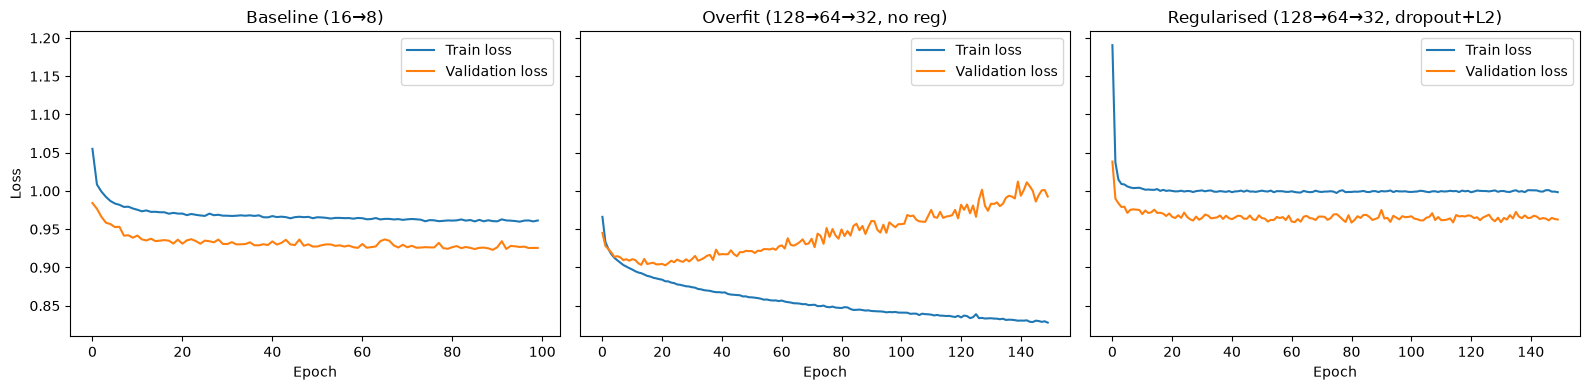


=== SUMMARY ===
Model                              Val Accuracy   
Baseline                           0.573          
Overfit                            0.574          
Regularised                        0.566          


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)

for ax, history, title in zip(
    axes,
    [history_baseline, history_overfit, history_regularised],
    ["Baseline (16→8)", "Overfit (128→64→32, no reg)", "Regularised (128→64→32, dropout+L2)"],
):
    ax.plot(history.history["loss"], label="Train loss")
    ax.plot(history.history["val_loss"], label="Validation loss")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.legend()

axes[0].set_ylabel("Loss")
plt.tight_layout()
plt.show()

print("\n=== SUMMARY ===")
print(f"{'Model':<35}{'Val Accuracy':<15}")
print(f"{'Baseline':<35}{acc_baseline:<15.3f}")
print(f"{'Overfit':<35}{acc_overfit:<15.3f}")
print(f"{'Regularised':<35}{acc_reg:<15.3f}")


## 9. Classification report — regularised model

In [10]:
print(classification_report(y_val, pred_reg, labels=np.arange(n_classes), target_names=le.classes_, zero_division=0))


              precision    recall  f1-score   support

        Base       0.53      0.69      0.60      9739
   Declining       0.60      0.49      0.54      7733
   Improving       0.59      0.46      0.52      6585
    Recovery       0.74      0.78      0.76       488

    accuracy                           0.57     24545
   macro avg       0.62      0.60      0.60     24545
weighted avg       0.57      0.57      0.56     24545

